# Receiving a collected diary and keeping it

Which correlations actually enter memory, and how long do they remain useful? Collection first supplies a quantum register. A receiving channel then transfers that register into a designated memory. Loss during acquisition and storage changes the final state on which recovery is attempted.

The untouched reference $Q$ labels the diary's original quantum information. The observer may already hold early radiation $E$. The incoming register $X$ contains the collected late carriers and their classical loss records. A deterministic decoder receives these available registers and flags, but cannot act on $Q$. Reference-assisted verification is a distinct measurement task that can access $Q$ at final comparison.

This notebook regenerates the catcher from propagated waveforms, evaluates both recovery-certificate procedures, and follows a separately specified exchange receiver through finite switching and storage loss. It then checks an exact five-share example in which storage noise reverses the preferred collection protocol. All failed outcomes remain in the scores.

In [1]:
from pathlib import Path
import os,sys,datetime,json,math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
sys.path.insert(0,str(Path('code').resolve()))
from receiver_storage import validate,exchange,survival,terminal_bounds,noisy_protocol,channel_checks
from recovery_certificates import statewise,catcher
from receiving_channels import caught_run,independent_absorber,deadline_scan
from causal_filter import channel_for_packets,FilterParameters
run_name=os.environ.get('ODER_RUN_NAME',datetime.datetime.now().strftime('%Y%m%d_%H%M%S'))
OUTPUT=Path('outputs/runs')/run_name/'storage';OUTPUT.mkdir(parents=True,exist_ok=True)
source=np.load('inputs/hp_joint_information.npy')
fresh_source=Path('outputs/runs')/run_name/'upstream/generated_source_information.npy'
if fresh_source.is_file():source=np.load(fresh_source)
registry=json.loads(Path('inputs/observer_registry.json').read_text())
print('Source information:', 'generated in this run' if fresh_source.is_file() else 'supplied subset arrays')

Source information: supplied subset arrays


## From detector output to retained memory

The detector's accumulated output and its current cavity occupation are distinct. The controlled catcher receives the output wave $y_j$, while the detector cavity remains a separate accessible register. Let $d_j(t)$ be the accumulated output energy. The startup regularizer $\varepsilon=10^{-6}$ keeps the control finite. Its retained probability is

$$m_j(t)=\frac{d_j(t)^2}{\varepsilon+d_j(t)},\qquad 0\le d_j-m_j\le\varepsilon.$$

Every label uses the same control. A survival mask therefore selects the corresponding source marginal, so the branch-resolved recovery certificates apply to the actual stored state. The next cell uses fresh upstream results if available; otherwise it uses the supplied propagation runs. It does not call cavity occupation durable storage.

In [2]:
runs={};caught={};certificate_rows=[]
for name in ['baseline','grid_refined','physical_refined']:
    fresh=Path('outputs/runs')/run_name/'upstream'/(name+'.npz')
    path=fresh if fresh.is_file() else Path('reference/upstream')/(name+'.npz')
    with np.load(path) as z:runs[name]={k:z[k] for k in z.files}
    current=caught_run(source,runs[name]);caught[name]=current
    rows=pd.DataFrame(current['certificates']);rows.insert(0,'propagation_run',name)
    certificate_rows.append(rows)
certificates=pd.concat(certificate_rows,ignore_index=True)
display(certificates[['propagation_run','source_index','no_early_branch_upper','full_early_branch_lower']])
certificates.to_csv(OUTPUT/'catcher_certificates.csv',index=False)
raw_upper=certificates.no_early_branch_upper.max();raw_lower=certificates.full_early_branch_lower.min()
rounded_upper=math.ceil(raw_upper*10000)/10000
rounded_lower=math.floor(raw_lower*10000)/10000
assert rounded_upper==.3306 and rounded_lower==.8472
print('Full precision extrema:',raw_upper,raw_lower)
print('Conservative stored-state certificates:',rounded_upper,rounded_lower)
np.savez_compressed(OUTPUT/'catcher_trajectories.npz',times=caught['baseline']['times'],memory=caught['baseline']['memory'],retained_information=caught['baseline']['retained_information'])

,propagation_run,source_index,no_early_branch_upper,full_early_branch_lower
0,baseline,0,0.322377,0.850734
1,baseline,1,0.325838,0.851881
2,baseline,2,0.330556,0.850605
3,baseline,3,0.325722,0.851071
4,baseline,4,0.327150,0.851334
...,...,...,...,...
91,physical_refined,27,0.323042,0.853758
92,physical_refined,28,0.328622,0.848811
93,physical_refined,29,0.324759,0.851918
94,physical_refined,30,0.325847,0.850734


Full precision extrema: 0.3305557714550558 0.8472465173720198
Conservative stored-state certificates: 0.3306 0.8472


### Check the absorbing dynamics separately

The closed-form catcher amplitude is $-d/\sqrt{\varepsilon+d}$. A second calculation integrates the absorber equation directly from the complex detector wave, together with its escaped output. It checks amplitude agreement and energy balance. The two methods share the physical model but use different evaluation paths.

For this multi-carrier catcher, the effective rate is calculated from the source-dependent information contraction. Its value decreases between the stated checkpoints, so this receiver does not satisfy the monotone-activation premise of the constant-kinetic strip benchmark.

In [3]:
checks=[]
baseline=runs['baseline']
for j in range(5):
    row=independent_absorber(baseline['times'],np.sqrt(.2575)*baseline['cavities'][:,j]);row['carrier']=j+1;checks.append(row)
display(pd.DataFrame(checks))
rates=caught['baseline']['effective_rate_59_120']
display(pd.DataFrame({'source_index':np.arange(32),'rate_at_59M':rates[0],'rate_at_120M':rates[1]}))
(OUTPUT/'catcher_checks.json').write_text(json.dumps(checks,indent=2)+'\n')

,balance_residual,amplitude_residual,terminal_retained,terminal_detector_output,carrier
0,6.584426e-15,5.107026e-15,0.428147,0.428148,1
1,4.109037e-15,3.108624e-15,0.447057,0.447058,2
2,2.346945e-15,1.776357e-15,0.450343,0.450344,3
3,1.987554e-15,1.554312e-15,0.450309,0.450310,4
4,1.354308e-15,1.110223e-15,0.447289,0.447290,5


,source_index,rate_at_59M,rate_at_120M
0,0,0.269155,0.257578
1,1,0.269202,0.257580
2,2,0.269166,0.257580
3,3,0.269172,0.257579
4,4,0.269122,0.257579
5,5,0.269183,0.257580
6,6,0.269208,0.257580
7,7,0.269127,0.257580
8,8,0.269252,0.257582
9,9,0.269163,0.257580


## Transfer an arbitrary collected register

A separate architecture transfers all of $X$ with input-independent probability $p$. Its transport-absence flag is orthogonal to every data word. With the early register retained, the terminal state is

$$\rho_{QEM}=p\rho_{QEX}\oplus(1-p)\rho_{QE}\otimes|\mathrm v\rangle\langle\mathrm v|.$$

Thus $I(Q:EM)=I(Q:E)+pI(Q:X\mid E)$. This holds even when the collected register contains imperfect diary correlations. A successful branch transfers the register without first decoding it.

Five collected qutrits have 243 data labels. Each receiving site needs one additional state for transport absence, giving 244 levels. The all-erased five-carrier word is a data label and remains distinct from transport absence. The Hamiltonian is the spatial exchange tensored with the identity on these labels. That symmetry permits a small spatial calculation while preserving every coherent input superposition and its reference correlations. Explicit entangled-state and Kraus-operator checks illustrate the resulting channel.

In [4]:
display(pd.DataFrame(channel_checks()))
validation=validate()
display(pd.DataFrame([x for x in validation['receiver_checks'] if 'sites' in x]))
print('Pulse area:',validation['pulse_area'])

,p,trace_preservation_residual,conditional_information_residual,choi_minimum_eigenvalue
0,0.00000,0.000000e+00,2.331468e-15,0.0
1,0.20000,1.570092e-16,2.664535e-15,0.0
2,0.88692,0.000000e+00,1.998401e-15,0.0
3,1.00000,0.000000e+00,8.881784e-16,0.0


,sites,memory_sites,no_loss_memory_population,retained_probability,norm_residual,uniform_loss_residual
0,2,[1],1.000000,0.886920,2.220446e-15,2.275957e-15
1,3,"[1, 2]",0.702064,0.622675,1.665335e-15,1.776357e-15


Pulse area: 1.5707963267948966


## A finite switch and two kinds of loss

The two-site exchange has $g/\Omega=5\pi/9$. Its envelope is one through $\Omega t=0.8$, then tapers with $1-3q^2+2q^3$ until $\Omega t=1$, where $q=(\Omega t-0.8)/0.2$ on the taper interval. The pulse area is $\pi/2$, so noiseless transfer is complete. Label-independent acquisition loss at rate $0.1\Omega$ and storage loss at rate $0.05\Omega$ for hold time $0.4/\Omega$ give $p=e^{-0.12}$.

Early radiation remains coherent and available to the joint decoder. The stated loss rates apply to the additional receiving and storage interval; no early-register noise is modeled. Acquisition lasts $1/\Omega$ and storage starts afterward. The preceding collection duration $120M$ and any decoder or final-readout duration remain separate resources.

The three-site control keeps its internal memory link $\sqrt6\Omega$ on while tapering only its source link $\sqrt2\Omega$. Memory occupies zero-indexed sites 1 and 2, the second and third sites. Its endpoint is numerical and has no two-site pulse-area identity. A shared available link bound does not match source variance or every physical resource.

In [5]:
two_p=survival();three_p=next(x['retained_probability'] for x in validation['receiver_checks'] if x.get('sites')==3)
no_early_information_max=max(x['no_early_information'] for x in statewise(source,baseline['observer_carriers'][-1]))
verification_lower=.375+.5*rounded_lower
verification_upper=math.ceil((.5+.5*np.sqrt(no_early_information_max*np.log(2)))*1e6)/1e6
terminal=[]
for name,p in [('two-site',two_p),('three-site',three_p)]:
    terminal.append(dict(receiver=name,p=p,**terminal_bounds(p,rounded_lower,rounded_upper,verification_lower,verification_upper)))
display(pd.DataFrame(terminal))
assert terminal[0]['full_early_lower']>.77966888
assert terminal[0]['no_early_upper']<.32148579
assert terminal[0]['verification_full_lower']>.76483444
assert terminal[0]['verification_no_early_upper']<.55274871
print('Three-site independent refinement:',validation['receiver_checks'][1])
pd.DataFrame(terminal).to_csv(OUTPUT/'switched_receiver_certificates.csv',index=False)

,receiver,p,full_early_lower,no_early_upper,full_early_universal_upper,verification_full_lower,verification_no_early_upper
0,two-site,0.886920,0.779669,0.321486,0.915190,0.764834,0.552749
1,three-site,0.622675,0.621861,0.300188,0.717006,0.685931,0.537033


Three-site independent refinement: {'check': 'three_site_refinement', 'midpoint_steps': [500, 1000, 2000], 'raw_amplitude_residuals': [2.2149527968185368e-08, 5.537363956248603e-09, 1.384323355633659e-09], 'richardson_residual': 3.651976711542037e-14}


## How long does the recovery guarantee survive?

At fixed acquisition loss, storage multiplies capture probability by $e^{-\kappa_sH}$. The full-early lower certificate guarantees fidelity greater than one half before $\Omega H\simeq15.415823$. The universal upper certificate excludes fidelity greater than one half from $\Omega H\simeq19.972246$ onward. The interval between them is unresolved by these bounds.

When the lower guarantee crosses the target, failure has not been proved. The obstruction uses the upper bound and constrains every decoder. The plotted hold time starts at the end of acquisition.

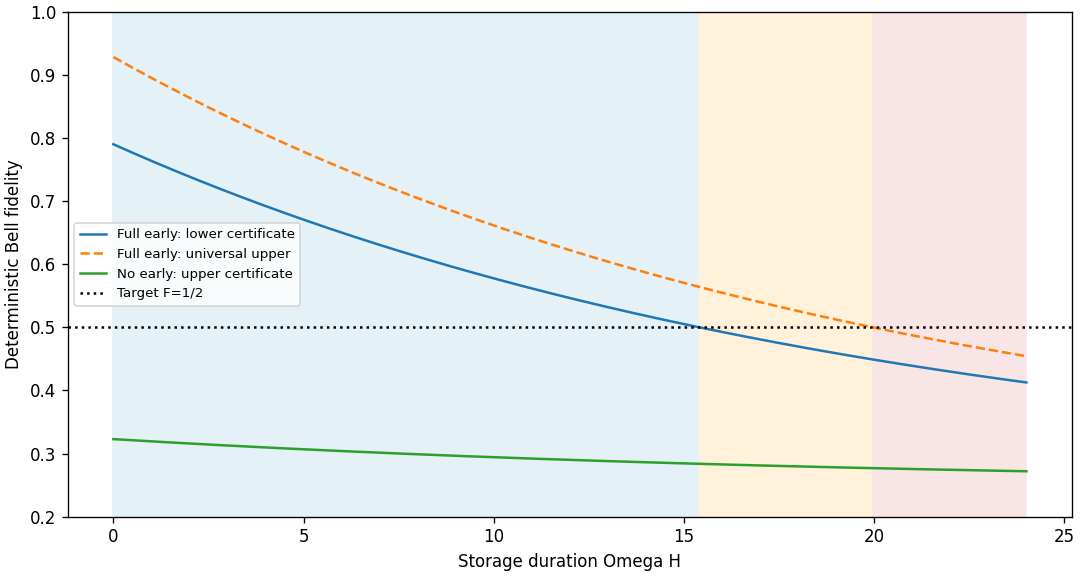

,guaranteed_before_OmegaH,obstructed_from_OmegaH,severe_loss_survival,severe_loss_universal_upper
0,15.415823,19.972246,0.272532,0.454399


In [6]:
hold=np.linspace(0,24,481);p=np.exp(-.1-.05*hold)
lower=.25+(rounded_lower-.25)*p;upper=.25+.75*p;noearly=.25+(rounded_upper-.25)*p
guarantee=validation['hold_guarantee'];obstruction=validation['hold_obstruction']
fig,ax=plt.subplots(figsize=(9,4.8),layout='constrained')
ax.axvspan(0,guarantee,color='#e4f1f7');ax.axvspan(guarantee,obstruction,color='#fff1da');ax.axvspan(obstruction,24,color='#f9e5e5')
ax.plot(hold,lower,label='Full early: lower certificate');ax.plot(hold,upper,'--',label='Full early: universal upper')
ax.plot(hold,noearly,label='No early: upper certificate');ax.axhline(.5,color='black',ls=':',label='Target F=1/2')
ax.set(xlabel='Storage duration Omega H',ylabel='Deterministic Bell fidelity',ylim=(.2,1));ax.legend(fontsize=8)
fig.savefig(OUTPUT/'storage_operating_region.png',dpi=170,metadata={'Software':None});plt.show()
severe=survival(.1,3.,.4)
assert .25+.75*severe<.45439885
display(pd.DataFrame([{'guaranteed_before_OmegaH':guarantee,'obstructed_from_OmegaH':obstruction,'severe_loss_survival':severe,'severe_loss_universal_upper':.25+.75*severe}]))
pd.DataFrame({'OmegaH':hold,'full_lower':lower,'full_upper':upper,'no_early_upper':noearly}).to_csv(OUTPUT/'storage_operating_curve.csv',index=False)

## Storage noise can reverse the collection preference

Keep the five-share code fixed. Protocol A activates all five receivers with probability 3/5 and otherwise none. Protocol B activates a uniformly selected triple. Each active share survives independently with probability $s$. Both protocols then have individual terminal efficiency $3s/5$.

The receiver mask is readable. Authorized terminal sets contain at least three shares and recover perfectly; every other branch has Bell overlap one quarter. Explicit activation and loss branches give

$$q_A(s)=\tfrac35(10s^3-15s^4+6s^5),\quad q_B(s)=s^3,\quad F=\tfrac14+\tfrac34q.$$

Factoring gives $q_A-q_B=s^3(5-9s+18s^2/5)$, with its only positive root in $[0,1]$ at $s=5/6$. The ordering reverses between loss doses 0.12 and 0.30.

Installed receivers, duration, per-link bound, and expected integrated control cost are matched. Peak active-link count and selector entropy differ. This is a fixed-encoding storage comparison; the MERA/tree intervention changes the encoding.

,protocol,survival,authorized_probability,bell_fidelity,individual_terminal_efficiency,activation_entropy_bits,peak_active_links,expected_active_links,expected_integrated_g2_over_Omega,loss_dose
0,A,0.886920,0.592729,0.694547,0.532152,0.970951,5,3.0,7.98968,0.12
1,B,0.886920,0.697676,0.773257,0.532152,3.321928,3,3.0,7.98968,0.12
2,A,0.740818,0.531939,0.648954,0.444491,0.970951,5,3.0,7.98968,0.30
3,B,0.740818,0.406570,0.554927,0.444491,3.321928,3,3.0,7.98968,0.30


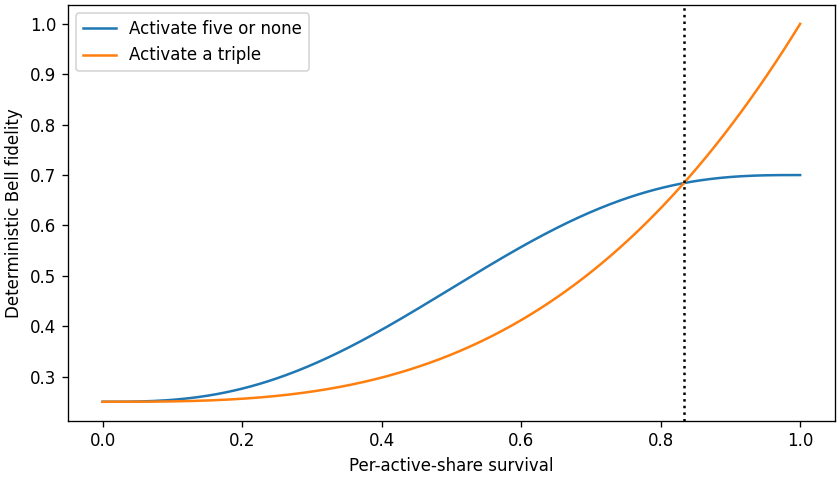

In [7]:
noise_rows=[];laws={}
for dose in [.12,.30]:
    for protocol in ['A','B']:
        row,law=noisy_protocol(np.exp(-dose),protocol);row['loss_dose']=dose;noise_rows.append(row);laws[f'{protocol}_{dose}']=law
display(pd.DataFrame(noise_rows))
pd.DataFrame(noise_rows).to_csv(OUTPUT/'noise_ordering.csv',index=False)
np.savez_compressed(OUTPUT/'noise_terminal_laws.npz',**laws)
s=np.linspace(0,1,401);a=.6*(10*s**3-15*s**4+6*s**5);b=s**3
fig,ax=plt.subplots(figsize=(7,4),layout='constrained');ax.plot(s,.25+.75*a,label='Activate five or none');ax.plot(s,.25+.75*b,label='Activate a triple')
ax.axvline(5/6,color='black',ls=':');ax.set(xlabel='Per-active-share survival',ylabel='Deterministic Bell fidelity');ax.legend()
fig.savefig(OUTPUT/'noise_ordering.png',dpi=170,metadata={'Software':None});plt.show()

## Verification uses a different interface

A failed recovery attempt does not establish destruction of reference correlations. In the five-share construction, unauthorized access gives the same restricted channel for preservation and reference erasure. An authorized set makes the logical diary available, and comparison with the retained reference can distinguish the hypotheses.

The following calculation forms the preserving and erased density matrices in the effective flagged logical channel. It evaluates their trace distance and checks that the memory-only states remain identical. Equal-prior optimal discrimination has success probability $1/2+3pq/8$, where $q$ is authorization probability and $p$ is subsequent capture probability. This measurement can use the reference; the recovery decoder cannot.

In [8]:
from reference_verification import discrimination
verification_rows=[discrimination(q,p) for q in [0.,.6,1.] for p in [0.,two_p,1.]]
display(pd.DataFrame(verification_rows))
pd.DataFrame(verification_rows).to_csv(OUTPUT/'reference_discrimination.csv',index=False)

,authorized_probability,capture_probability,reference_assisted_success,trace_distance,memory_only_state_difference
0,0.0,0.00000,0.500000,0.000000,0.000000e+00
1,0.0,0.88692,0.500000,0.000000,0.000000e+00
2,0.0,1.00000,0.500000,0.000000,0.000000e+00
3,0.6,0.00000,0.500000,0.000000,0.000000e+00
4,0.6,0.88692,0.699557,0.399114,7.850462e-17
5,0.6,1.00000,0.725000,0.450000,7.850462e-17
6,1.0,0.00000,0.500000,0.000000,0.000000e+00
7,1.0,0.88692,0.832595,0.665190,1.570092e-16
8,1.0,1.00000,0.875000,0.750000,1.570092e-16


## Allocate a fixed lifetime to collection and delivery

For delivery to a separate final register, collection and capture share a fixed $120M$ budget. The finite 63-site Hamiltonian stays fixed, with $h=1$ and $\Omega=0.025/M$. The catcher supplies a sourcewise lower certificate at each cutoff. The chain's uniform probability-error bound supplies a conservative capture floor for the remaining duration.

The code scans the saved 0.05M cutoff grid and evaluates both stated schedules on every supplied propagation refinement. The result is a grid-selected certificate optimum. If the catcher itself is the allowed final memory, continued collection is a different, stronger architecture; this delivery optimization does not make a serial receiver universally necessary.

In [9]:
allocation=[]
for name,run in caught.items():
    result=deadline_scan(source,run)
    for row in result['selected']:allocation.append(dict(propagation_run=name,**row))
display(pd.DataFrame(allocation));pd.DataFrame(allocation).to_csv(OUTPUT/'deadline_allocation.csv',index=False)
(OUTPUT/'channel_validation.json').write_text(json.dumps(validation,indent=2)+'\n')

,propagation_run,cutoff,capture_duration,exact_finite_capture,analytic_probability_error,certified_capture_floor,worst_source_fidelity_lower,limiting_source_index
0,baseline,80.0,40.0,0.823622,4.275736e-07,0.823621,0.695156,25
1,baseline,74.4,45.6,0.886613,3.124627e-05,0.886582,0.705627,25
2,grid_refined,80.0,40.0,0.823622,4.275736e-07,0.823621,0.695156,25
3,grid_refined,74.4,45.6,0.886613,3.124627e-05,0.886582,0.705627,25
4,physical_refined,80.0,40.0,0.823622,4.275736e-07,0.823621,0.695156,25
5,physical_refined,74.4,45.6,0.886613,3.124627e-05,0.886582,0.705627,25


Ending collection at $74.4M$ leaves $45.6M$ for delivery and raises the worst-source certified fidelity from about 0.69516 for the $80M$ cutoff to about 0.70563. The earlier cutoff sacrifices collection time but improves delivery enough to strengthen the final guarantee. This is the best point on the stated scan, not a continuous optimum.

## Receive a fixed number of recorded arrivals

A smaller receiving register can accept the first $m$ late carriers and leave diary decoding until after capture. The arrival record says which carriers are present, so the backend transports $2^m$ coherent labels rather than all five qutrit slots. Each site needs $2^m+1$ levels, including transport absence. Early radiation stays in its existing register.

This is a separate time-recorded front end on the same propagated detector output. Its acceptance density is $\dot m_j(t)$, with $m_j=d_j^2/(\varepsilon+d_j)$. The time record preserves the dual-rail logical value. These one-time probabilities match the coherent catcher; the additional instrument supplies event histories rather than inferring them from saved marginals. The numerical CDF is piecewise linear on the saved time grid.

Collection ends at the $m$th accepted carrier. A declared loading interval $\ell$ packs that subset into the receiving source. This is routing time, not decoder execution time. Buffering, routing, early storage and terminal holding are lossless. The source-dependent decoder acts after acquisition and has its own execution budget.

For first-gate density $f_S(h)$, capture kernel $p(T,h)$ and source entry $J_{s,S}$, the all-trial lower certificate is

$$F_s(T)\ge\frac14+\sum_{|S|=m}\int f_S(h)p(T,h)\left(2^{2J_{s,S}-2}-\frac14\right)dh.$$

Every source is evaluated before taking the minimum. A common constant Markov hazard gives exact scalar closure for the designated post-gate information. A finite Jacobi chain initialized at each gate instead keeps its age-dependent cohort kernel. The latter uses the existing $h=1$, $N=62$, $\Omega=0.025/M$ chain, disconnects the source after at most $57.15M$, and holds captured information until $T=120M$. The cutoff is selected once on the stated duration grid, independently of the source and gate outcome.


In [10]:
from progressive_receivers import save as save_progressive
progressive = save_progressive(OUTPUT/'progressive', source, runs)
progressive_rows = pd.DataFrame(progressive['rows'])
finite_gate = progressive_rows[progressive_rows.receiving_mode=='finite_chain_reset']
finite_table = finite_gate.groupby(['gate_count','receiving_site_levels','loading_delay_M'])['worst_source_fidelity_lower'].min().unstack('loading_delay_M')
display(finite_table)
print('Recorded-gate mass residual:', progressive['metadata']['maximum_gate_mass_residual'])
print('Quadrature fidelity difference:', progressive['metadata']['maximum_quadrature_fidelity_difference'])
assert progressive['metadata']['source_count']==32
assert progressive['metadata']['maximum_gate_mass_residual']<1e-10
assert progressive['metadata']['maximum_quadrature_fidelity_difference']<1e-9
assert finite_table.loc[(2,5),0.]>.6731
assert finite_table.loc[(2,5),10.]>.6393


,loading_delay_M,0.0,2.0,5.0,10.0,20.0
gate_count,receiving_site_levels,,,,,
1,3,0.609011,0.607705,0.605374,0.600301,0.584192
2,5,0.673135,0.667735,0.658407,0.639304,0.586771
3,9,0.484152,0.478265,0.468388,0.449197,0.402358
4,17,0.319776,0.317108,0.312742,0.304626,0.286659
5,33,0.258864,0.258414,0.257692,0.256399,0.253759


Recorded-gate mass residual: 3.6637359812630166e-15
Quadrature fidelity difference: 1.2212453270876722e-15


The two-carrier gate gives the strongest lower certificate among the five tested count gates for loading intervals $0$, $5M$ and $10M$. Its floors are at least $0.6731$, $0.6584$ and $0.6393$, with five local levels per receiving site. Zero loading is an ideal routing benchmark; nonzero loading times are supplied budgets rather than measured circuit timings.

The larger-code serial receiver reaches a higher floor, $0.7056$, using 244 levels per site. The gate offers a receiving-register tradeoff. Chain length and coupling scale are matched; arrival records, conditional packing, upstream buffers and decoder control remain separate resources. Unrestricted recovery from the continuing catcher can emulate the gated terminal state by post-processing and remains the stronger access resource.

The exact common-clock law and the age-reset finite-chain certificate answer different questions. Neither assumes that partial HP information becomes an exact authorization threshold.


## What these results establish

The catcher calculation evaluates stored reference information from the detector output. Uniform whole-register transfer preserves arbitrary input correlations through its flagged channel. The finite switch, acquisition loss, and storage loss then enter terminal recovery and verification through that channel, with every failed outcome included.

Recorded progressive collection adds a persistent gate and fixed-size receiving code, with sourcewise deadline certificates and explicit loading times. Its common-clock law is distinguished from the finite receiver's age-dependent kernel.

The storage curves identify a guaranteed region, an unresolved interval, and a decoder-independent obstruction. The five-share example shows why matched individual efficiencies do not fix the performance after storage. Its resource accounting and the MERA/tree intervention answer different physical questions.

The coverage and execution record is in `VERIFICATION.md`.
